# Teleportación, caminatas cuánticas y swap test con qang

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Viny2030/qang/blob/main/notebooks/qang_tp_teleport_walks_swap_es.ipynb)

Tres temas con código ejecutable, ruido simulado de dispositivos IBM y figuras para presentar:

1. **Teleportación**: el protocolo, su fidelidad en un dispositivo con ruido, y por qué con pérdidas el recurso óptimo **no** es un par de Bell.
2. **Caminatas cuánticas**: propagación balística (cuántica) contra difusiva (clásica), y cómo el ruido convierte una en la otra salvo que se use el filtro qg.
3. **Swap test y kernels**: medir la fidelidad entre dos estados, cuántos disparos hacen falta, y un clasificador basado en kernels.

Todo corre en simuladores locales de dispositivos IBM (`FakeTorino`, con su modelo de ruido calibrado): sin cuenta ni hardware. Unos 3–4 minutos. Las figuras se guardan en `figuras_tp/`.

**qang en una línea:** un qubit se describe por lo que se mide, qg_Z = ⟨Z⟩ (y el ángulo qang arccos qg_Z). Cuando un circuito conserva el número de excitaciones, los disparos que lo violan se descartan: es el **filtro qg**.

## 0. Instalación y configuración

In [1]:
import importlib, subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "qang", "qiskit-aer", "qiskit-ibm-runtime", "scikit-learn", "matplotlib"], check=False)
importlib.invalidate_caches()
try:
    import qang.qpon
    ok = hasattr(qang.qpon, "fidelity_from_correlators")
except ImportError:
    ok = False
if not ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--force-reinstall", "--no-deps",
                    "git+https://github.com/Viny2030/qang.git"], check=True)
    print("qang instalado desde GitHub; si falla un import, reiniciá el entorno una vez")
import qang
print("qang", qang.__version__)

qang 0.12.0


In [2]:
import math, os, time
import numpy as np
import matplotlib.pyplot as plt
import qiskit_ibm_runtime.fake_provider as fp
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qang import algorithms as AL, ibm, qpon as Q, kernels as KR, statistics as ST

os.makedirs("figuras_tp", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
BACKEND = "FakeTorino"
T0 = time.time()


def run(circuits, shots=4000, seed=7, backend=BACKEND):
    """Transpila a un dispositivo IBM simulado y muestrea con su ruido; devuelve los conteos."""
    b = getattr(fp, backend)()
    ts = transpile(circuits, b, optimization_level=1, seed_transpiler=137)
    res = AerSimulator.from_backend(b).run(ts, shots=shots, seed_simulator=seed).result()
    return [res.get_counts(i) for i in range(len(circuits))]


def bit(key, q):
    return int(key.replace(" ", "")[-1 - q])

---
# 1. Teleportación

**Idea.** Alice quiere enviarle a Bob un estado cuántico desconocido |ψ⟩ sin mandarle el qubit. Comparten un par de Bell; Alice mide su qubit junto con |ψ⟩ en la base de Bell y le manda 2 bits clásicos; Bob aplica una corrección (X, Z) y obtiene |ψ⟩. No se copia nada (el original se destruye) y no hay comunicación más rápida que la luz (sin los 2 bits Bob no tiene nada).

**Cómo se mide en qang.** La fidelidad promedio sobre la esfera de Bloch se obtiene con los 6 estados cardinales (|0⟩, |1⟩, |±⟩, |±i⟩), que forman un *3-diseño esférico*: su promedio es exacto. El límite clásico (medir y reenviar) es F = 2/3.

In [3]:
qc = AL.teleportation_circuit((1.1, 0.4))
print(qc.draw(output="text"))
print("fidelidad ideal para varios estados:", [round(AL.teleportation_output_fidelity((t, p)), 6) for t, p in ((0, 0), (1.1, 0.4), (2.5, -1.0))])

# en el dispositivo simulado: la teleportación de qang.qpon con fibra perfecta (T = 1) y sin divisor (N = 1)
# es el protocolo estándar con un par de Bell (alpha = pi/4)
cs = run([Q.teleport_circuit(math.pi / 4, 1.0, 1, k) for k in range(6)])
r = Q.fidelity_from_counts(cs)
print(f"fidelidad promedio en {BACKEND}: {r['fidelity']:.3f} ± {r['se']:.3f}   (ideal 1, límite clásico 2/3)")
print("por estado de entrada:", {k: round(float(v), 3) for k, v in zip(Q.INPUTS, r["per_input"])})

     ┌─────────┐┌─────────┐     ┌───┐   
q_0: ┤ Ry(1.1) ├┤ Rz(0.4) ├──■──┤ H ├─■─
     └──┬───┬──┘└─────────┘┌─┴─┐└───┘ │ 
q_1: ───┤ H ├────────■─────┤ X ├──■───┼─
        └───┘      ┌─┴─┐   └───┘┌─┴─┐ │ 
q_2: ──────────────┤ X ├────────┤ X ├─■─
                   └───┘        └───┘   
fidelidad ideal para varios estados: [1.0, 1.0, 1.0]


fidelidad promedio en FakeTorino: 0.968 ± 0.001   (ideal 1, límite clásico 2/3)
por estado de entrada: {'0': 0.964, '1': 0.967, '+': 0.969, '-': 0.969, '+i': 0.967, '-i': 0.969}


## 1.1 Con pérdidas el recurso óptimo no es un par de Bell (§157)

En una red óptica pasiva (fibra con transmisión T y un divisor 1:N), el fotón de Bob llega con probabilidad η = T/N. Si el recurso es cos α|00⟩ + sin α|11⟩, la fidelidad es

F(α) = (2f + 1)/3,  f = (cos α + √η sin α)² / (2 (cos²α + κ sin²α))

y el óptimo es **tan α\* = √η / κ**, no α = π/4 (par de Bell). Es el análogo de qubits del *squeezing óptimo finito* de la teleportación de variable continua. κ = 1 si nadie ayuda; si los otros usuarios avisan cuando el fotón les llegó a ellos (protocolo **asistido**), esos disparos se descartan —un filtro de sector— y κ = η + 1 − T.

Abajo: N = 8 usuarios, sin pérdida de fibra. Curvas = fórmula; puntos = dispositivo simulado.

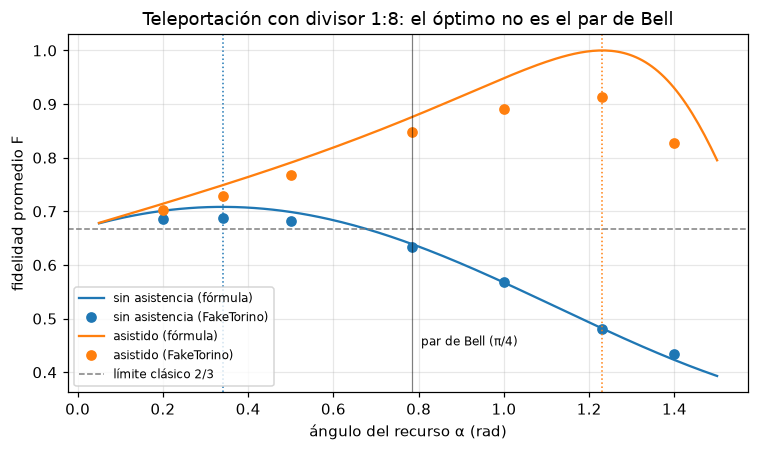

sin asistencia: par de Bell F = 0.639 (< 2/3), óptimo α* = 0.340 con F* = 0.708 (> 2/3)
regla de diseño en qg: el qubit del recurso debe medir qg_Z* = +0.778


In [4]:
L, N = 0, 8
T = Q.fibre_transmission(L)
alphas = np.linspace(0.05, 1.5, 200)
grid = [0.2, 0.34, 0.5, math.pi / 4, 1.0, 1.23, 1.4]
cs = run([Q.teleport_circuit(a, T, N, k) for a in grid for k in range(6)])
meas = {p: [Q.fidelity_from_counts(cs[6 * i:6 * i + 6], p == "asistido")["fidelity"] for i in range(len(grid))]
        for p in ("sin asistencia", "asistido")}

fig, ax = plt.subplots(figsize=(7, 4.2))
for p, assisted, col in (("sin asistencia", False, "C0"), ("asistido", True, "C1")):
    eta, kap = Q.link(L, N, assisted)
    ax.plot(alphas, [Q.average_fidelity(a, eta, kap) for a in alphas], color=col, label=f"{p} (fórmula)")
    ax.plot(grid, meas[p], "o", color=col, label=f"{p} ({BACKEND})")
    a_star = Q.optimal_angle(eta, kap)
    ax.axvline(a_star, color=col, ls=":", lw=1)
ax.axhline(2 / 3, color="gray", ls="--", lw=1, label="límite clásico 2/3")
ax.axvline(math.pi / 4, color="k", lw=0.8, alpha=0.5)
ax.text(math.pi / 4 + 0.02, 0.45, "par de Bell (π/4)", fontsize=8)
ax.set(xlabel="ángulo del recurso α (rad)", ylabel="fidelidad promedio F",
       title=f"Teleportación con divisor 1:{N}: el óptimo no es el par de Bell")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig("figuras_tp/teleportacion_optimo.png", dpi=200); plt.show()

eta, _ = Q.link(L, N)
print(f"sin asistencia: par de Bell F = {Q.average_fidelity(math.pi / 4, eta):.3f} (< 2/3), "
      f"óptimo α* = {Q.optimal_angle(eta):.3f} con F* = {Q.optimal_fidelity(eta):.3f} (> 2/3)")
print(f"regla de diseño en qg: el qubit del recurso debe medir qg_Z* = {Q.optimal_qg_z(eta):+.3f}")

## 1.2 Predecir la fidelidad sin teleportar (§158)

La fidelidad que dará un recurso es una lectura lineal de tres correladores qg: **F = (3 + qg_XX − qg_YY + qg_ZZ) / 6**. Tres circuitos cortos (sin medición de Bell) predicen la fidelidad.

In [5]:
for p, assisted in (("sin asistencia", False), ("asistido", True)):
    a = Q.optimal_angle(*Q.link(0, 4, assisted))
    cs = run([Q.resource_circuit(a, 1.0, 4, b) for b in "XYZ"] + [Q.teleport_circuit(a, 1.0, 4, k) for k in range(6)])
    corr = [Q.correlator_from_counts(c, assisted)[0] for c in cs[:3]]
    print(f"{p:15s}: qg_XX {corr[0]:+.3f}, qg_YY {corr[1]:+.3f}, qg_ZZ {corr[2]:+.3f} -> F predicha "
          f"{Q.fidelity_from_correlators(*corr):.3f};  F teleportada {Q.fidelity_from_counts(cs[3:], assisted)['fidelity']:.3f}")

sin asistencia : qg_XX +0.373, qg_YY -0.405, qg_ZZ +0.674 -> F predicha 0.742;  F teleportada 0.735


asistido       : qg_XX +0.916, qg_YY -0.922, qg_ZZ +0.927 -> F predicha 0.961;  F teleportada 0.939


---
# 2. Caminatas cuánticas

**Clásica:** un caminante en una línea da pasos al azar; la varianza de su posición crece **linealmente**, σ² ∝ t (difusión). **Cuántica:** el caminante está en superposición de posiciones y los caminos interfieren; σ² ∝ **t²** (propagación balística, mucho más rápida). Es la base de búsquedas en grafos y del transporte cuántico de energía.

**En un circuito.** Una excitación en una cadena de n qubits con acoplamiento XX + YY (cadena XY) salta entre vecinos: es una caminata cuántica en tiempo continuo. Todas las compuertas conservan el número de excitaciones (1), así que el filtro qg aplica: se descartan los disparos con 0 o 2 excitaciones, que solo pueden venir del ruido.

**Qué esperar (§147, 21 dispositivos):** crudos, los datos con ruido parecen una caminata clásica (exponente de σ² contra t ≈ 0.87); con el filtro vuelve a ser balística (1.84; ideal 1.94).

In [6]:
n, MID = 7, 3
TIMES = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6]
DT = 0.2


def sigma2(p):
    p = np.clip(np.asarray(p, float), 0, None); p = p / p.sum()
    return float(p @ (np.arange(len(p)) - MID) ** 2)


def occupations(counts, filtered):
    occ, tot = np.zeros(n), 0
    for k, c in counts.items():
        b = [bit(k, q) for q in range(n)]
        if filtered and sum(b) != 1:
            continue
        occ += c * np.array(b); tot += c
    return occ / tot


ideal = {t: ibm.xy_exact_occupations(n, 1.0, None, t, MID) for t in TIMES}
cs = run([ibm.xy_trotter(n, 1.0, None, t, int(round(t / DT)), initial=(MID,)) for t in TIMES])
raw = {t: occupations(c, False) for t, c in zip(TIMES, cs)}
filt = {t: occupations(c, True) for t, c in zip(TIMES, cs)}
kept = [sum(v for k, v in c.items() if k.replace(" ", "").count("1") == 1) / sum(c.values()) for c in cs]

fit = lambda s2: np.polyfit(np.log(TIMES), np.log(np.maximum(s2, 1e-6)), 1)[0]
s2 = {name: [sigma2(d[t]) for t in TIMES] for name, d in (("ideal", ideal), ("crudo", raw), ("filtrado qg", filt))}
s2["caminata clásica"] = [2 * 1.0 * t for t in TIMES]   # difusión con la misma tasa de salto: sigma^2 = 2 J t
for k, v in s2.items():
    print(f"{k:17s} exponente de sigma^2 ~ t^a: a = {fit(v):.2f}")
print("fracción de disparos conservada por el filtro:", np.round(kept, 3))

ideal             exponente de sigma^2 ~ t^a: a = 1.97
crudo             exponente de sigma^2 ~ t^a: a = 0.51
filtrado qg       exponente de sigma^2 ~ t^a: a = 1.67
caminata clásica  exponente de sigma^2 ~ t^a: a = 1.00
fracción de disparos conservada por el filtro: [0.674 0.65  0.606 0.588 0.565 0.546 0.525 0.488]


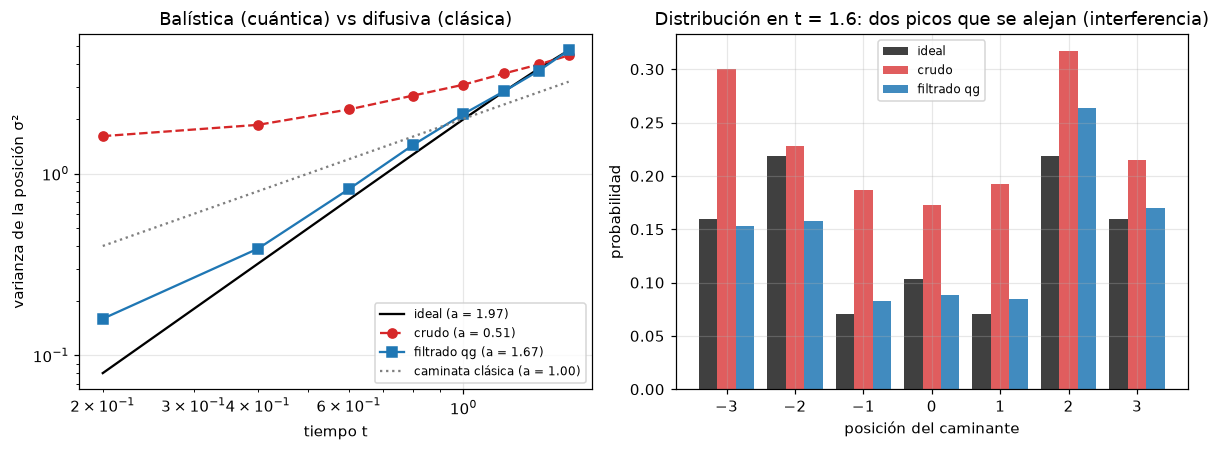

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axs[0]
for (k, v), sty in zip(s2.items(), ("k-", "C3o--", "C0s-", "C7:")):
    ax.loglog(TIMES, v, sty, label=f"{k} (a = {fit(v):.2f})")
ax.set(xlabel="tiempo t", ylabel="varianza de la posición σ²", title="Balística (cuántica) vs difusiva (clásica)")
ax.legend(fontsize=8)
ax = axs[1]
t = 1.6
x = np.arange(n) - MID
w = 0.27
ax.bar(x - w, ideal[t], w, color="k", alpha=0.75, label="ideal")
ax.bar(x, raw[t], w, color="C3", alpha=0.75, label="crudo")
ax.bar(x + w, filt[t], w, color="C0", alpha=0.85, label="filtrado qg")
ax.set(xlabel="posición del caminante", ylabel="probabilidad", title=f"Distribución en t = {t}: dos picos que se alejan (interferencia)")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figuras_tp/caminata_cuantica.png", dpi=200); plt.show()

**Lectura.** La distribución ideal tiene dos picos que se alejan del centro (interferencia), no una campana que se ensancha. El ruido la aplana hacia el centro (parece clásica); el filtro qg recupera los picos.

---
# 3. Swap test, cantidad de disparos y kernels

**Swap test.** Para dos estados |x⟩, |y⟩ y un qubit auxiliar: H, SWAP controlado, H; entonces P(auxiliar = 0) = (1 + |⟨x|y⟩|²)/2. Mide la **fidelidad** F = |⟨x|y⟩|² sin conocer los estados.

**Test de inversión** (alternativa): cargar x, deshacer la carga de y; F = P(volver al estado inicial). Usa la mitad de qubits y, en codificación unaria (un qubit por componente, una excitación), todas las compuertas conservan el peso, así que el filtro qg aplica de lleno. En el swap test la respuesta está en el auxiliar, *fuera* de la simetría, y el filtro ayuda poco (§149).

inversión crudo     error medio 0.065   (estados idénticos: 0.770, ideal 1)
inversión filtrado  error medio 0.009   (estados idénticos: 0.982, ideal 1)
swap crudo          error medio 0.134   (estados idénticos: 0.538, ideal 1)
swap filtrado       error medio 0.086   (estados idénticos: 0.743, ideal 1)


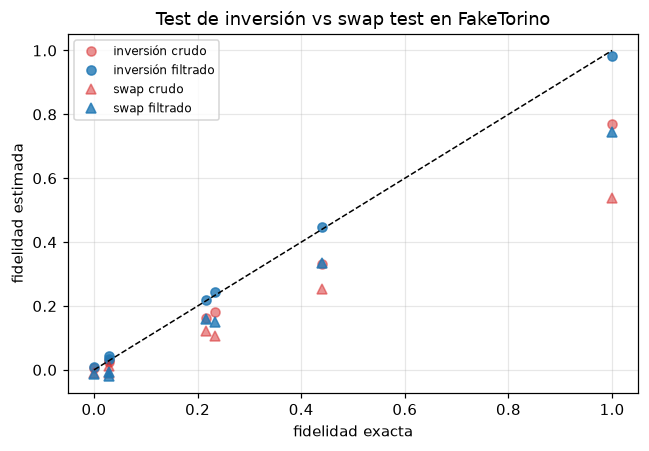

In [8]:
rng = np.random.default_rng(149)
vecs = [v / np.linalg.norm(v) for v in rng.normal(size=(6, 4))]
pairs = [(vecs[i], vecs[j]) for i, j in ((0, 1), (0, 2), (1, 3), (2, 4), (3, 5), (4, 5))] + [(vecs[0], vecs[0])]
exact = np.array([(x @ y) ** 2 for x, y in pairs])
inv = [KR.kernel_from_counts(c) for c in run([ibm.unary_overlap_circuit(x, y) for x, y in pairs])]
sw_counts = run([ibm.swap_test_circuit(x, y) for x, y in pairs])
m = len(pairs[0][0])


def swap_fid(c, filtered):
    tot = a0 = 0
    for k, v in c.items():
        data = sum(bit(k, q) for q in range(1, 2 * m + 1))
        if filtered and data != 2:
            continue
        tot += v; a0 += v * (bit(k, 0) == 0)
    return 2 * a0 / tot - 1


est = {"inversión crudo": [e["raw"] for e in inv], "inversión filtrado": [e["filtered"] for e in inv],
       "swap crudo": [swap_fid(c, False) for c in sw_counts], "swap filtrado": [swap_fid(c, True) for c in sw_counts]}
for k, v in est.items():
    print(f"{k:19s} error medio {np.mean(np.abs(np.array(v) - exact)):.3f}   (estados idénticos: {v[-1]:.3f}, ideal 1)")

fig, ax = plt.subplots(figsize=(6, 4.2))
for (k, v), mk in zip(est.items(), ("C3o", "C0o", "C3^", "C0^")):
    ax.plot(exact, v, mk, alpha=0.8 if "filtrado" in k else 0.5, label=k)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="fidelidad exacta", ylabel="fidelidad estimada", title=f"Test de inversión vs swap test en {BACKEND}")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figuras_tp/swap_vs_inversion.png", dpi=200); plt.show()

## 3.1 ¿Cuántos disparos? (complejidad de muestreo)

Cada estimación es una proporción de disparos, así que su error baja como **1/√N**. qang da intervalos de confianza (Wilson) en unidades qg; el ángulo qang tiene un error ≈ 1/√N independiente del estado (§125). Abajo: el intervalo de 95% de la fidelidad de un par, con un simulador sin ruido, al crecer N.

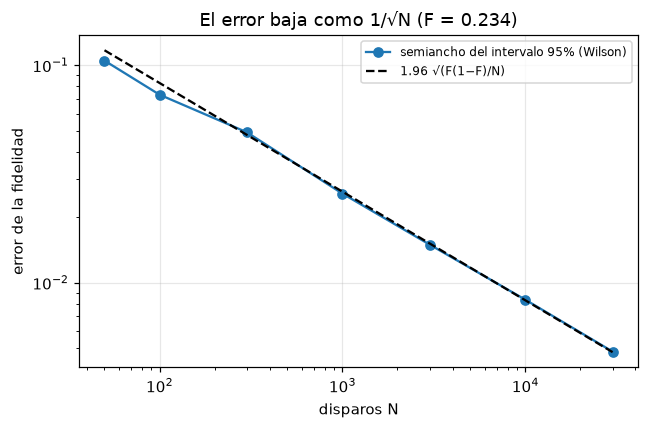

para error ±0.01 hacen falta unos 6882 disparos


In [9]:
x, y = pairs[2]
F = (x @ y) ** 2
ns = [50, 100, 300, 1000, 3000, 10000, 30000]
half = []
qc = ibm.unary_overlap_circuit(x, y)
sim = AerSimulator(seed_simulator=3)
for N in ns:
    c = sim.run(transpile(qc, sim), shots=N).result().get_counts()
    k1 = sum(v for k, v in c.items() if bit(k, 0) == 1 and k.count("1") == 1)
    e = ST.wilson_qg_estimate(N - k1, N)            # Wilson para p0 = 1 - F, en unidades qg (qg = 2 p0 - 1)
    half.append((e.high - e.low) / 4)               # semiancho del intervalo de F
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(ns, half, "o-", label="semiancho del intervalo 95% (Wilson)")
ax.loglog(ns, [1.96 * math.sqrt(F * (1 - F) / N) for N in ns], "k--", label="1.96 √(F(1−F)/N)")
ax.set(xlabel="disparos N", ylabel="error de la fidelidad", title=f"El error baja como 1/√N (F = {F:.3f})")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("figuras_tp/disparos_error.png", dpi=200); plt.show()
print("para error ±0.01 hacen falta unos", int(math.ceil((1.96 / 0.01) ** 2 * F * (1 - F))), "disparos")

## 3.2 Un clasificador con kernel cuántico (§161)

El kernel de fidelidad K(x, y) = |⟨x|y⟩|² es la matriz de "parecidos" que usa una máquina de vectores soporte (QSVC). Con ruido, la matriz de Gram se contrae (K(x, x) < 1). La reparación habitual divide por la diagonal; con un circuito que conserva el peso, el filtro qg la repara mejor y sin circuitos extra. Datos: cáncer de mama (scikit-learn), 4 componentes principales, 20 + 20 puntos.

kernel exacto: 17/20 aciertos
crudo                  error de la matriz 0.0876   aciertos 17/20   diagonal media 0.718
crudo + normalizado    error de la matriz 0.0207   aciertos 17/20   diagonal media 0.718
filtrado               error de la matriz 0.0152   aciertos 17/20   diagonal media 0.971
filtrado + normalizado error de la matriz 0.0132   aciertos 17/20   diagonal media 0.971


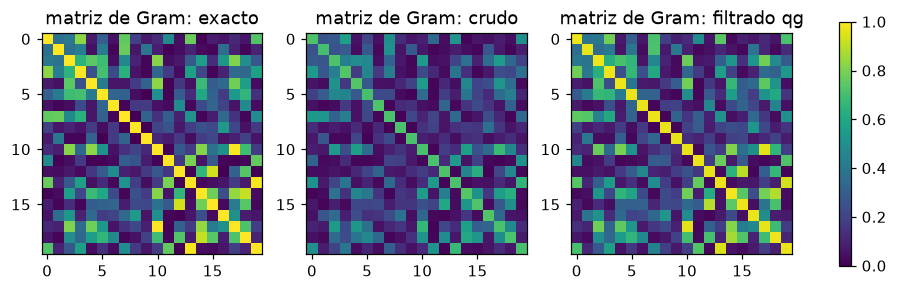

tiempo total 150 s


In [10]:
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.svm import SVC
X, yl = load_breast_cancer(return_X_y=True)
rng = np.random.default_rng(161)
tr = np.concatenate([rng.choice(np.where(yl == c)[0], 10, replace=False) for c in (0, 1)])
rest = np.setdiff1d(np.arange(len(yl)), tr)
te = np.concatenate([rng.choice(rest[yl[rest] == c], 10, replace=False) for c in (0, 1)])
mu, sd = X[tr].mean(0), X[tr].std(0)
p = PCA(4).fit((X[tr] - mu) / sd)
A, Bt = (KR.unary_embedding(p.transform((X[i] - mu) / sd)) for i in (tr, te))
ntr, nte = len(tr), len(te)
pr = [(A[i], A[j]) for i in range(ntr) for j in range(ntr)] + [(Bt[i], A[j]) for i in range(nte) for j in range(ntr)]
pr += [(Bt[i], Bt[i]) for i in range(nte)]
est = [KR.kernel_from_counts(c) for c in run([ibm.unary_overlap_circuit(a, b) for a, b in pr], shots=2000)]
K0 = KR.exact_kernel(A, A)
acc = lambda Ktr, Kte: int((SVC(kernel="precomputed").fit(Ktr, yl[tr]).predict(Kte) == yl[te]).sum())
iu = np.triu_indices(ntr, 1)
print(f"kernel exacto: {acc(K0, KR.exact_kernel(Bt, A))}/{nte} aciertos")
mats = {}
for kind, name in (("raw", "crudo"), ("filtered", "filtrado")):
    v = np.array([e[kind] for e in est])
    Ktr, Kte, dte = v[:ntr * ntr].reshape(ntr, ntr), v[ntr * ntr:ntr * ntr + nte * ntr].reshape(nte, ntr), v[-nte:]
    dtr = np.diag(Ktr)
    for label, (Kt, Ke) in ((name, (Ktr, Kte)), (name + " + normalizado", (KR.normalize_gram(Ktr, dtr, dtr), KR.normalize_gram(Kte, dte, dtr)))):
        mats[label] = Kt
        print(f"{label:22s} error de la matriz {np.abs(Kt[iu] - K0[iu]).mean():.4f}   aciertos {acc(Kt, Ke)}/{nte}   diagonal media {dtr.mean():.3f}")
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (title, M) in zip(axs, (("exacto", K0), ("crudo", mats["crudo"]), ("filtrado qg", mats["filtrado"]))):
    im = ax.imshow(M, vmin=0, vmax=1, cmap="viridis"); ax.set_title(f"matriz de Gram: {title}"); ax.grid(False)
fig.colorbar(im, ax=axs, shrink=0.8)
fig.savefig("figuras_tp/kernel_gram.png", dpi=200, bbox_inches="tight"); plt.show()
print(f"tiempo total {time.time() - T0:.0f} s")

---
## Resumen para la presentación

| Tema | Mensaje | Número clave |
|---|---|---|
| Teleportación | Con pérdidas, el recurso óptimo no es el par de Bell; su qg_Z es la regla de diseño | con 8 usuarios: Bell < 2/3, óptimo > 2/3 |
| Teleportación | La fidelidad se predice con tres correladores qg | F = (3 + qg_XX − qg_YY + qg_ZZ)/6 |
| Caminatas cuánticas | El ruido hace parecer clásica a una caminata cuántica; el filtro qg recupera la propagación balística | exponente ≈ 1 crudo → ≈ 2 filtrado |
| Swap test | El test de inversión (dentro de la simetría) se filtra mucho mejor que el swap test (respuesta en el auxiliar) | error varias veces menor |
| Disparos | El error baja como 1/√N | ±0.01 requiere miles de disparos |
| Kernels | El filtro qg repara la matriz de Gram mejor que la normalización diagonal | precisión casi igual: el SVM compara valores |

Más detalle: `RESEARCH_NOTES.md` §147, §149, §157, §158, §161 y los notebooks `qang_qpon_teleport_es`, `qang_methods_es`, `qang_ibm_recent`.